# Topology optimization of a waveguide bend in 3D: a 0.4 µm nitride core in oxide

**Question.** The [2D bend tutorial](bend.ipynb) optimizes a 90° turn in a slab
model, where two effective indices stand for the vertical stack. Here the stack is
real: a silicon nitride (Si3N4) core 0.4 µm thick in silica (SiO2), with guides
0.8 µm wide. In the 3 µm × 3 µm square where the two guides meet, through the
core's thickness, each point may be nitride or oxide. Which pattern carries the most
power at 1.55 µm from the fundamental TE-like mode of one guide into that of the
other, and where does the power it loses go: through the sides of the box, or out
of the plane of the chip?

A core 0.4 µm thick holds light more loosely than the 2D model's core does: the
guide's mode index lies close to the oxide's, and its field reaches well into the
oxide around the core. How much of the power can a 3 µm square turn at all?

**What the run found.** The optimized design, `final`, carries 0.216 of the
incident power into the output guide's mode, against 0.049 for a circular arc of
1.5 µm radius and 0.0004 for a sharp corner. Of the 0.783 it loses, 0.091 leaves
through the top and bottom of the stack and the rest radiates in the plane. The
checks below (power balance, reciprocity, the mirror, the mesh and the box) hold,
the re-solves moving |S21|² by at most 1.0 × 10⁻³, so 0.216 is what this stack
gives in this square, not an error of the model.

The recipe is the 2D tutorial's: pixels ρ → Helmholtz filter → projection → layer
grid → material field → `gfem.solve` → S21, with
[optax](https://optax.readthedocs.io)'s Adam on the pixels. This page explains only
what changes in 3D.

**This page solves nothing.** The optimization and its checks ran once, outside CI
and the docs build, as `tools/bend3d_run.py` (about 1 h on 16 cores and 64 GiB,
with the `mkl` extra). The run wrote a **run record** next to this notebook:
`data/bend3d.json` (provenance, settings and resource observations) and
`data/bend3d.npz` (every solver output). Each number below is computed from the
complex S-matrices and arrays in the record. The code shown is included from the
script that ran, and the first cell stops the page if that script, or the mesh
builder it imports, is no longer the one in the repository.

**Assumptions.**

- Lossless media at their 1.55 µm indices, constant over the band: Si3N4 from the
  LPCVD Sellmeier fit of Luke et al., Opt. Lett. 40, 4823 (2015), and SiO2 from
  Malitson, J. Opt. Soc. Am. 55, 1205 (1965).
- No substrate: 1.6 µm of oxide above and below the core, then the boundary.
- A second-order absorbing boundary on every outer face, the top and bottom
  included, instead of a PML: 1 µm from the design square in plane and 1.6 µm
  from the core vertically.
- The design is uniform through the core: vertical sidewalls and a full etch. The
  stack and every design are then mirror-symmetric about the core's mid-plane z = 0.
- **Mirror half model.** The fundamental TE-like mode is even about z = 0, so the
  model keeps z ≥ 0 and puts a PMC on z = 0. It solves half the volume for the same
  S-matrix; one re-solve on the full stack checks this.
- Second-order Nédélec elements on a structured tetrahedral mesh, with in-plane
  cells of at most 0.1 µm for the optimization; one re-solve at 0.07 µm checks the
  mesh.

**Conventions.** SI units at the API (the meshes are in µm), time dependence
e^{+iωt}, S-parameters as power waves normalized to 1 W of mode power at each wave
port (see `gfem.conventions`). On the mirror half model the 1 W flows through the
half of the port window above z = 0; the full stack carries the mirror image, so
|S21|² is the same fraction of the incident power in both.

In [1]:
import hashlib
import json
import os
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from contourpy import contour_generator

ROOT, DATA = Path("../.."), Path("data")
record = json.loads((DATA / "bend3d.json").read_text())
with np.load(DATA / "bend3d.npz") as npz:
    out = {key: npz[key] for key in npz.files}
provenance, settings, seen = (
    record[key] for key in ("provenance", "settings", "observations")
)

RERUN = (
    "rerun it with `just bend3d-data` (tools/bend3d_run.py, about 1 h on 16 cores "
    "and 64 GiB with the mkl extra) and commit the new data/bend3d.json and .npz"
)
for script, recorded in provenance["sha256"].items():
    current = hashlib.sha256((ROOT / script).read_bytes()).hexdigest()
    if current != recorded:
        raise RuntimeError(
            f"{script} has changed since it wrote the run record (sha256 "
            f"{current[:12]}, recorded {recorded[:12]}), so the record's numbers "
            f"are not this script's: {RERUN}."
        )
if record["profile"] != "full" and os.environ.get("GFEM_BEND3D_ALLOW_SMOKE") != "1":
    raise RuntimeError(
        f"data/bend3d.json is a {record['profile']!r} run, a development check; "
        f"this page publishes the full run: {RERUN}. Set GFEM_BEND3D_ALLOW_SMOKE=1 "
        "to read it anyway."
    )

stages = provenance["stages"]
start = min(datetime.fromisoformat(s["start_utc"]) for s in stages.values())
end = max(datetime.fromisoformat(s["end_utc"]) for s in stages.values())
versions = provenance["versions"]
print(
    f"run record: {record['profile']} profile, run on {start:%Y-%m-%d}, gfem "
    f"{versions['gfem']} at commit {provenance['commit'][:12]}"
)
print(
    f"machine: {provenance['cpu_model']}, {provenance['physical_cores']} cores "
    f"({provenance['threads']} threads), "
    f"{provenance['memory_limit_bytes'] / 2**30:.0f} GiB, {provenance['os']}; "
    f"NGSolve {versions['ngsolve']}, JAX {versions['jax']}, MKL {versions['mkl']} "
    f"(PARDISO {'available' if provenance['pardiso_available'] else 'absent'})"
)
print(
    f"wall time: {(end - start).total_seconds() / 60:.1f} min, from the first "
    "stage's start to the last stage's end; the stages, one process each:"
)
for name, stage in stages.items():
    print(f"  {name}: {stage['command']}")

run record: full profile, run on 2026-10-23, gfem 0.1.0.dev0 at commit bc1dae936e8f
machine: AMD EPYC 7V73X 64-Core Processor, 16 cores (16 threads), 64 GiB, Debian GNU/Linux 12 (bookworm); NGSolve 6.2.2608, JAX 0.12.0, MKL 2026.2.0 (PARDISO available)
wall time: 72.0 min, from the first stage's start to the last stage's end; the stages, one process each:
  optimize: python tools/bend3d_run.py optimize --out work --profile full
  half: python tools/bend3d_run.py half --out work --profile full
  spectrum: python tools/bend3d_run.py spectrum --out work --profile full
  full: python tools/bend3d_run.py full --out work --profile full
  box: python tools/bend3d_run.py box --out work --profile full
  fine: python tools/bend3d_run.py fine --out work --profile full


## The stack

The box is the 2D tutorial's 5 µm × 5 µm in plane, centred on the bend, now
3.6 µm tall: a Si3N4 core 0.4 µm thick at |z| < 0.2 µm, with SiO2 to |z| = 1.8 µm.
The input guide runs along x < -1.5 µm and the output guide along y < -1.5 µm,
both 0.8 µm wide; the design volume is the square |x|, |y| < 1.5 µm through the
core. `tools/bend3d_mesh.py` builds the meshes at run time, with node lines on every
material edge; none is committed.

Each wave port is a window 4.0 µm wide on its guide's end face (|y| < 2.0 µm on
x = -2.5 µm for p1, |x| < 2.0 µm on y = -2.5 µm for p2), through the full height,
whose edges on the absorbing faces are conducting (`pec_edges`). Mode 1 of each
port, the one the S-matrix uses, is the guide's fundamental TE-like mode. The
model, as the run built it:

```{literalinclude} ../../tools/bend3d_run.py
:pyobject: model
```

Below, the indices recomputed from the cited Sellmeier formulas (stored in the
record), the port modes' effective indices, and a check on the model itself: a
**straight guide** on the same cross-section, 5 µm long with p2 on x = +2.5 µm and
no bend. Its remainder 1 - |S11|² - |S21|² is the power the model loses along a
guide that should lose none: the part of any remainder below that the bend does not
cause.

In [2]:
um = 1e-6
geometry, cuts, fluxes = (settings[key] for key in ("geometry", "cuts", "fluxes"))
HALF, DESIGN = geometry["box_half_width_um"], geometry["design_half_width_um"]
GUIDE, CORE_HALF = geometry["core_width_um"] / 2, geometry["core_thickness_um"] / 2
Z_TOP = geometry["z_um"][1]  # the top of the stack
PORT = geometry["port_window_half_width_um"]  # half the width of a port window
PITCH = settings["pitch_um"]
indices = settings["indices"]
N_CLADDING = indices["cladding"]["n"]


def sellmeier(wavelength_um, terms):
    # n^2 = 1 + sum B l^2 / (l^2 - C^2), with (B, C in um) in terms.
    l2 = wavelength_um**2
    return np.sqrt(1 + sum(b * l2 / (l2 - cc**2) for b, cc in terms))


def mesh(stage, kind="bend"):
    # The record's entry for the mesh a stage solved on: h, tetrahedra, DOF.
    (entry,) = (
        m
        for m in settings["meshes"].values()
        if stage in m["stages"] and m["kind"] == kind
    )
    return entry


def powers(s):
    # |S21|^2, |S11|^2, |S22|^2 and |S12 - S21| of S[..., to, from] over (p1, p2).
    s = np.asarray(s)
    return (
        np.abs(s[..., 1, 0]) ** 2,
        np.abs(s[..., 0, 0]) ** 2,
        np.abs(s[..., 1, 1]) ** 2,
        np.abs(s[..., 0, 1] - s[..., 1, 0]),
    )


def transmission(key):
    # |S21|^2 of a stored S-matrix: the power out of p2 in its fundamental mode.
    return float(powers(out[key])[0])


def report(name, key):
    sent, back = transmission(key), float(powers(out[key])[1])
    print(
        f"{name}: |S21|^2 = {sent:.4f}, |S11|^2 = {back:.1e}, "
        f"remainder = {1 - sent - back:.4f}"
    )
    return sent


for entry in indices.values():
    n = [sellmeier(lam, entry["sellmeier"]) for lam in (1.2, 1.55, 1.8)]
    print(
        f"{entry['material']}: n = {n[1]:.6f} at 1.55 um (the model's "
        f"{entry['n']:.6f}); {n[0]:.4f} at 1.2 um, {n[2]:.4f} at 1.8 um"
    )
n_eff = np.real(out["n_eff"])
optimized_on = mesh("optimize")
print(
    f"port modes, h = {optimized_on['h_um']} um mirror half model: n_eff = "
    f"{n_eff[0]:.6f} (p1), {n_eff[1]:.6f} (p2), between {N_CLADDING:.6f} and "
    f"{indices['core']['n']:.6f}"
)
decay = settings["wavelength_um"] / (2 * np.pi * np.sqrt(n_eff[0] ** 2 - N_CLADDING**2))
print(
    f"  the mode's field decays by 1/e every {decay:.2f} um into the oxide: "
    "1/gamma, with gamma = k0 sqrt(n_eff^2 - n_SiO2^2)"
)
print(
    f"  each window: |y| or |x| < {PORT:g} um on its end face, |z| < {Z_TOP:g} um "
    "on the full stack"
)
straight = mesh("half", kind="straight")
print(
    f"straight guide, {geometry['straight_guide_length_um']:g} um, "
    f"h = {straight['h_um']} um:"
)
t_straight = report("  straight guide", "s_straight")

Si3N4: n = 1.996280 at 1.55 um (the model's 1.996280); 2.0065 at 1.2 um, 1.9893 at 1.8 um
SiO2: n = 1.444024 at 1.55 um (the model's 1.444024); 1.4481 at 1.2 um, 1.4409 at 1.8 um
port modes, h = 0.1 um mirror half model: n_eff = 1.599506 (p1), 1.599506 (p2), between 1.444024 and 1.996280
  the mode's field decays by 1/e every 0.36 um into the oxide: 1/gamma, with gamma = k0 sqrt(n_eff^2 - n_SiO2^2)
  each window: |y| or |x| < 2 um on its end face, |z| < 1.8 um on the full stack
straight guide, 5 um, h = 0.1 um:
  straight guide: |S21|^2 = 0.9993, |S11|^2 = 2.0e-09, remainder = 0.0007


Both ports solve the same mode, n_eff = 1.599506: between the oxide's 1.444 and
the nitride's 1.996, and much nearer the oxide. The field falls by 1/e only every
0.36 µm into the oxide beside the core: the guide holds its mode loosely. The
straight guide transmits 0.9993 and loses 0.0007 over 5 µm with no bend.

Left, the port plane x = -2.5 µm to scale, white core in black oxide: the p1
window (solid) with its conducting edges, the absorbing faces around it
(dash-dotted: the rest of the end face, and the top, bottom and sides seen edge-on),
and the mirror plane z = 0 (dotted), above which the mirror half model lies. Right, the top view of the core layer with the design square at 0.5,
where the optimization starts, p1 solid and p2 dashed.

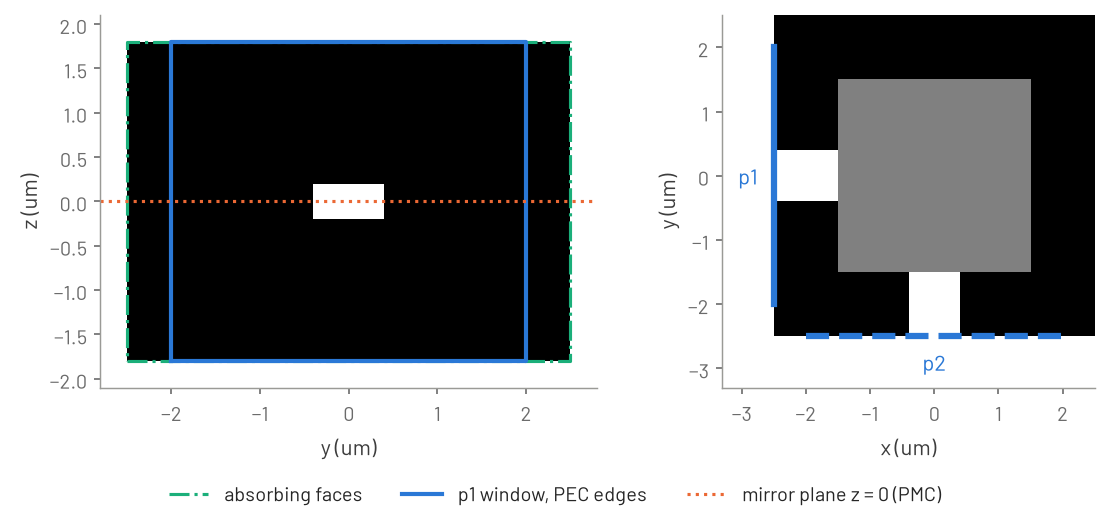

In [3]:
centres = -HALF + (np.arange(round(2 * HALF / PITCH)) + 0.5) * PITCH  # pixel centres
X, Y = np.meshgrid(centres, centres)  # rows y, columns x
ARMS = ((X < -DESIGN) & (np.abs(Y) < GUIDE)) | ((Y < -DESIGN) & (np.abs(X) < GUIDE))
IN_DESIGN = (np.abs(X) < DESIGN) & (np.abs(Y) < DESIGN)
EXTENT = [-HALF, HALF, -HALF, HALF]


def window(density):
    # The core layer of the whole box as a pixel image: the guides around a design.
    image = ARMS.astype(float)
    image[IN_DESIGN] = np.ravel(density)
    return image


heights = -Z_TOP + (np.arange(round(2 * Z_TOP / PITCH)) + 0.5) * PITCH
S, Z = np.meshgrid(centres, heights)  # across the guide, up the stack
section = ((np.abs(S) < GUIDE) & (np.abs(Z) < CORE_HALF)).astype(float)

fig, (side, top) = plt.subplots(
    1,
    2,
    figsize=(8, 3.4),
    width_ratios=[2 * HALF, 2 * HALF + 0.8],
    layout="constrained",
)
side.imshow(
    section,
    origin="lower",
    extent=[-HALF, HALF, -Z_TOP, Z_TOP],
    cmap="gray",
    vmin=0,
    vmax=1,
)
box = np.array([[-1, -1], [1, -1], [1, 1], [-1, 1], [-1, -1]])
side.plot(*(box * [HALF, Z_TOP]).T, color="C2", ls="-.", label="absorbing faces")
side.plot(
    *(box * [PORT, Z_TOP]).T, color="C0", ls="-", lw=2, label="p1 window, PEC edges"
)
side.axhline(0, color="C1", ls=":", lw=1.5, label="mirror plane z = 0 (PMC)")
side.set_xlim(-HALF - 0.3, HALF + 0.3)  # the boundary lines clear of the image edge
side.set_ylim(-Z_TOP - 0.3, Z_TOP + 0.3)
side.set_xlabel("y (um)")
side.set_ylabel("z (um)")

top.imshow(
    window(out["rho_start"]), origin="lower", extent=EXTENT, cmap="gray", vmin=0, vmax=1
)
for port, (lo, hi), style in (
    ("p1", ([-HALF, -PORT], [-HALF, PORT]), "-"),
    ("p2", ([-PORT, -HALF], [PORT, -HALF]), "--"),
):
    top.plot([lo[0], hi[0]], [lo[1], hi[1]], color="C0", ls=style, lw=3)
    middle = (np.array(lo) + np.array(hi)) / 2  # the label sits outside the image
    top.text(*middle * (1 + 0.4 / HALF), port, color="C0", ha="center", va="center")
top.set_xlim(-HALF - 0.8, HALF)
top.set_ylim(-HALF - 0.8, HALF)
top.set_xlabel("x (um)")
top.set_ylabel("y (um)")
fig.legend(loc="outside lower center", ncols=3);

Two hand-drawn bends set the scale before any optimization, the 2D tutorial's
rebuilt for 0.8 µm guides. The **arc design** is a quarter ring 0.8 µm wide, of
radius 1.5 µm about the corner (-1.5, -1.5) µm; the **corner design** extends both
guides until they meet in a sharp L. Their pixels hold the area fraction of core.
Each is one driven solve at 1.55 µm with both ports excited, on the mirror half
model.

The media are lossless, so the remainder 1 - |S11|² - |S21|² is power that leaves
port 1's mode for neither port's fundamental mode. Unlike the 2D slab's 0.55 µm
guide, the 0.8 µm strip guides no second TE-like mode at 1.55 µm (its cutoff width
is about 1.08 µm), and TE-like and TM-like modes do not couple in a stack and design
symmetric about z = 0. The remainder is therefore radiation: in plane, through the
side faces, and out of plane, through the top and bottom.

In [4]:
t_arc = report("arc design", "s_arc")
t_corner = report("corner design", "s_corner")

arc design: |S21|^2 = 0.0489, |S11|^2 = 2.0e-05, remainder = 0.9511
corner design: |S21|^2 = 0.0004, |S11|^2 = 1.3e-02, remainder = 0.9863


The arc keeps 0.049 of the power in the guide and the corner 0.0004. Neither
reflects much (|S11|² is at most 0.013), so nearly all the rest is radiated. A
radius of 1.5 µm is the largest the 3 µm square allows, and at that radius the
mode leaves the arc's outer edge instead of turning with it, as the field maps
below show. The optimization starts from this scale.

## From pixels to a material

The chain is the 2D tutorial's (see its section of the same name): 60 × 60 pixels
of 0.05 µm over the design square, mirrored about y = x, a Helmholtz filter of
radius 0.3 µm, and a projection of sharpness β. Each mesh element takes the pixel
image at its centroid, and the design is uniform through the core. A pixel value of
0 is SiO2 and 1 is Si3N4, with ε_r linear in between.

```{literalinclude} ../../tools/bend3d_run.py
:pyobject: layer_grid
```

```{literalinclude} ../../tools/bend3d_run.py
:pyobject: density_filter
```

```{literalinclude} ../../tools/bend3d_run.py
:pyobject: physical
```

```{literalinclude} ../../tools/bend3d_run.py
:pyobject: material
```

## Optimize

The objective is the 2D one, 1 - |S21|² at 1.55 µm, from one driven solve with both
ports excited. `has_aux` returns |S21|² and the core fraction with the gradient:

```{literalinclude} ../../tools/bend3d_run.py
:pyobject: missed_power
```

What changes is the solver. The mirror half model at h = 0.1 µm (its size is
printed below) is solved by the sparse direct solver: PARDISO, from the `mkl`
extra. A gradient reuses the forward factorization in the backward pass when
the retained memory budget holds it, so the run keeps 4 GiB instead of the 512 MiB
default:

```{literalinclude} ../../tools/bend3d_run.py
:pyobject: solver_options
```

The loop is the 2D tutorial's (`optimize` in the script): Adam with step 0.1 on the
raw pixels, clipped to [0, 1], from a uniform 0.5; β doubles from 1 to 32 every 7
steps, 42 iterations in all. Below, the schedule as recorded and the time each
iteration took on the run's machine: observations of that machine, not benchmarks.

In [5]:
schedule = settings["schedule"]
t_history, core_history = out["t_history"], out["core_history"]
seconds = out["seconds_history"]
n_steps, steps_per_beta = schedule["iterations"], schedule["steps_per_beta"]
print(
    f"{n_steps} iterations: beta = {', '.join(f'{b:g}' for b in schedule['betas'])}, "
    f"{steps_per_beta} each; {schedule['optimizer']}({schedule['learning_rate']}), "
    f"clipped to {schedule['clip']}, from {schedule['start']}"
)
print(
    f"mesh: h = {optimized_on['h_um']} um, mirror half model, "
    f"{optimized_on['tets']:,} tetrahedra, {optimized_on['dof']:,} DOF at order "
    f"{settings['order']}"
)
print(
    f"one solve and its gradient: median {np.median(seconds[1:]):.1f} s, "
    f"{seconds[1:].min():.1f} to {seconds[1:].max():.1f} s over iterations 1 to "
    f"{n_steps - 1}; iteration 0, with the JIT compilation, {seconds[0]:.1f} s"
)
optimize_stage = seen["optimize"]
print(
    f"optimize stage: {optimize_stage['wall_s'] / 60:.1f} min, peak memory "
    f"{optimize_stage['peak_rss_bytes'] / 2**30:.1f} GiB"
)

42 iterations: beta = 1, 2, 4, 8, 16, 32, 7 each; optax.adam(0.1), clipped to [0.0, 1.0], from 0.5
mesh: h = 0.1 um, mirror half model, 165,000 tetrahedra, 1,081,222 DOF at order 2
one solve and its gradient: median 46.6 s, 44.0 to 54.6 s over iterations 1 to 41; iteration 0, with the JIT compilation, 48.1 s
optimize stage: 33.0 min, peak memory 29.8 GiB


|S21|² and the core fraction per iteration. The dotted black line is the arc
design's |S21|²; the thin grey lines mark where β doubles. |S21|² passes the arc's
within the first seven iterations, at β = 1. After that it rises most where β
doubles, by smaller steps each time, and is nearly flat over the last seven
iterations. The core fraction rises from 0.5 and settles near 0.6.

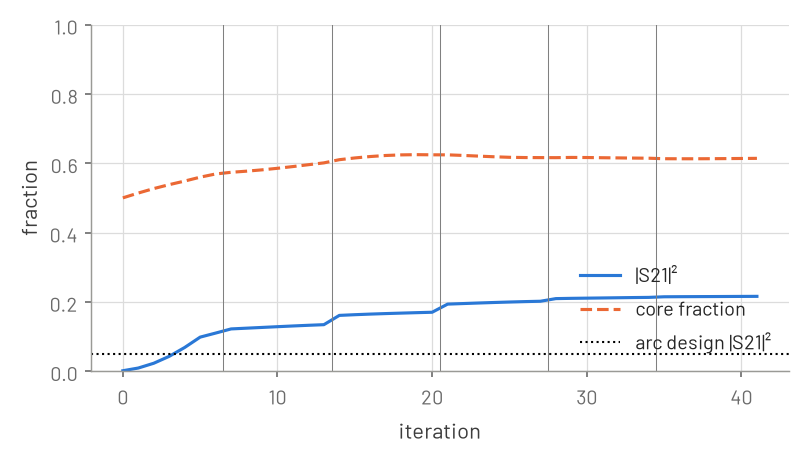

In [6]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(t_history, label="|S21|²")
ax.plot(core_history, label="core fraction")
ax.axhline(t_arc, color="k", ls=":", lw=1, label="arc design |S21|²")
for k in range(steps_per_beta, n_steps, steps_per_beta):
    ax.axvline(k - 0.5, color="gray", lw=0.5)
ax.set_ylim(0, 1)
ax.set_xlabel("iteration")
ax.set_ylabel("fraction")
ax.legend(loc="lower right");

## The design

The physical density at four evenly spaced iterations, white Si3N4 and black SiO2,
with each iteration's |S21|². From the uniform start the design forms a wide strip
of nitride that joins the two guides along the inner corner, with narrower curved
strips outside it, roughly parallel to it and broken into segments. By iteration 41
(β = 32) it is nearly binary.

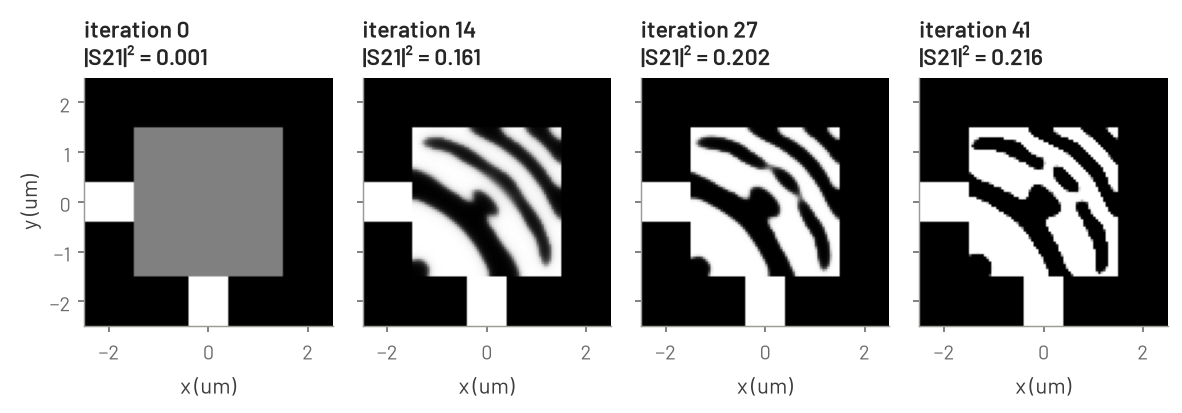

In [7]:
snapshot_at = out["snapshot_iterations"]
fig, axes = plt.subplots(1, 4, figsize=(8, 2.6), sharey=True)
for ax, k, density in zip(axes, snapshot_at, out["snapshots"], strict=True):
    ax.imshow(
        window(density), origin="lower", extent=EXTENT, cmap="gray", vmin=0, vmax=1
    )
    ax.set_title(f"iteration {k}\n|S21|² = {t_history[k]:.3f}")
    ax.set_xlabel("x (um)")
axes[0].set_ylabel("y (um)")
fig.tight_layout();

The design we evaluate is `final`: the last physical density (after the last Adam
step, at the last β) thresholded at 0.5, a two-material image. Every number after
this is about `final`, except the eroded and dilated variants below. Here, |S21|²
of the last iterate next to that of `final`, and the share of the last density's
pixels already within 0.05 of 0 or 1.

In [8]:
last, final = out["last"], out["final"]
t_last, t_final = transmission("s_last"), transmission("s_final")
print(f"iteration {n_steps - 1}: |S21|^2 = {t_history[-1]:.4f} (before its Adam step)")
print(f"last density, beta = {schedule['betas'][-1]:g}: |S21|^2 = {t_last:.4f}")
print(
    f"final: |S21|^2 = {t_final:.4f}, thresholded at {settings['threshold']}, "
    f"{final.mean():.1%} core"
)
binary = np.mean((last < 0.05) | (last > 0.95))
print(f"{binary:.1%} of the last density's pixels lie within 0.05 of 0 or 1")

iteration 41: |S21|^2 = 0.2158 (before its Adam step)
last density, beta = 32: |S21|^2 = 0.2160
final: |S21|^2 = 0.2161, thresholded at 0.5, 61.4% core
96.5% of the last density's pixels lie within 0.05 of 0 or 1


Thresholding changes little: the last density transmits 0.2160 and `final`
0.2161, since 96.5 % of the last density's pixels were already within 0.05 of 0 or
1. `final` is 61.4 % nitride. It transmits more than four times what the arc does,
and about a fifth of the incident power.

`final` in 3D, seen from above the output guide's side: the oxide see-through, the
core (tan, translucent) with `final`'s core pixels as blocks through the 0.4 µm core,
and two field cuts on one grey scale: |E| on the core mid-plane z = 0 and across the
input guide at x = -2.0 µm, through the full height. Port p1 is fed with 1 W
incident; |E| is scaled to its peak on the input guide in the mid-plane. The fields
come from the mirror half model and are mirrored about z = 0 for the view, where the
TE-like field is even.

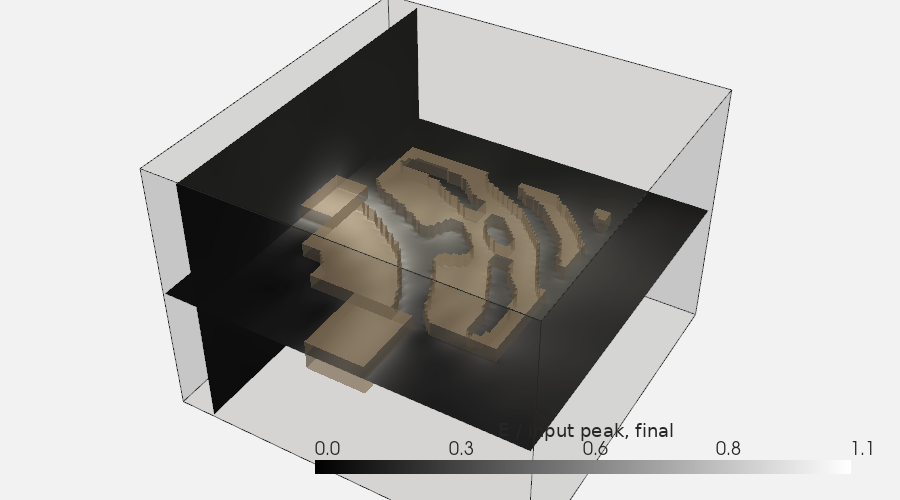

In [9]:
import pyvista as pv

pv.set_jupyter_backend("static")
VIEW = (0.6, -1, 0.9)  # the camera's direction: above, on the output guide's side
cut_x, cut_y, cut_z = (out[key] / um for key in ("cut_x", "cut_y", "cut_z"))
input_peak = {  # |E| peak in the input guide's part of the mid-plane cut
    name: out[f"cut_top_{name}"][:, cut_x < -DESIGN].astype(float).max()
    for name in ("final", "arc")
}


def mirrored(cut):
    # A cut over z >= 0 (columns z) as the full height, z from -1.8 to 1.8 um.
    return np.concatenate([cut[:, ::-1], cut], axis=1).astype(float)


def plane(u, v, values, place):
    # A sampled cut as a surface: values (len(u), len(v)) at points place(U, V).
    U, V = np.meshgrid(u, v, indexing="ij")
    surface = pv.StructuredGrid(*place(U, V))
    surface.point_data["|E|"] = values.ravel(order="F")
    return surface


every = 2  # every other sample: 100 x 100 points on the mid-plane
heights_full = np.concatenate([-cut_z[::-1], cut_z])
surfaces = [
    plane(
        cut_x[::every],
        cut_y[::every],
        (out["cut_top_final"].astype(float).T / input_peak["final"])[::every, ::every],
        lambda U, V: (U, V, np.zeros_like(U)),
    ),
    plane(
        cut_y[::every],
        heights_full[::every],
        mirrored(out["cut_in_final"])[::every, ::every] / input_peak["final"],
        lambda U, V: (np.full_like(U, cuts["cut_in_x_um"]), U, V),
    ),
]
blocks = pv.ImageData(
    dimensions=(final.shape[1] + 1, final.shape[0] + 1, 2),
    spacing=(PITCH, PITCH, 2 * CORE_HALF),
    origin=(-DESIGN, -DESIGN, -CORE_HALF),
)
blocks.cell_data["core"] = final.ravel().astype(float)  # x fastest: rows are y
core = [
    pv.Box((-HALF, -DESIGN, -GUIDE, GUIDE, -CORE_HALF, CORE_HALF)),
    pv.Box((-GUIDE, GUIDE, -HALF, -DESIGN, -CORE_HALF, CORE_HALF)),
    blocks.threshold(0.5, scalars="core"),
]
oxide = pv.Box((-HALF, HALF, -HALF, HALF, -Z_TOP, Z_TOP))
peak = max(c["|E|"].max() for c in surfaces)

view = pv.Plotter(window_size=(900, 500))
view.add_mesh(oxide, color="lightgrey", opacity=0.15)
view.add_mesh(oxide.outline(), color="black")
for part in core:
    view.add_mesh(part, color="tan", opacity=0.5)
for c in surfaces:
    view.add_mesh(
        c,
        scalars="|E|",
        cmap="gray",
        clim=(0, peak),
        scalar_bar_args={"title": "|E| / input peak, final", "fmt": "%.1f"},
    )
view.view_vector(VIEW, viewup=(0, 0, 1))
view.camera.zoom(1.3)
view.show()

## Trust: power balance and reciprocity

One driven solve of `final` at 1.55 µm with both ports excited, on the mirror half
model at the optimization's mesh, fields kept for the measurements below. Three
properties of the model must show in it:

- **Power balance.** The media are lossless and the model is passive, so
  |S11|² + |S21|² ≤ 1. The remainder 1 - |S11|² - |S21|² is radiation, in plane and
  out of plane (see above); the straight guide's remainder is the part of it the
  bend does not cause.
- **Reciprocity.** The media are reciprocal, so S12 = S21.
- **Symmetry.** The design and the mesh are mirror images about y = x, so
  |S11|² = |S22|².

In [10]:
_, r11, r22, recip = (float(v) for v in powers(out["s_final"]))
print(f"final at F0: |S21|^2 = {t_final:.4f}, |S11|^2 = {r11:.1e}, |S22|^2 = {r22:.1e}")
print(f"reciprocity: |S12 - S21| = {recip:.1e}")
print(f"power balance: |S11|^2 + |S21|^2 = {r11 + t_final:.6f}, at most 1")
remainder = 1 - r11 - t_final
print(
    f"remainder, radiated in or out of plane: {remainder:.4f}; straight guide: "
    f"{1 - t_straight - float(powers(out['s_straight'])[1]):.1e}"
)

final at F0: |S21|^2 = 0.2161, |S11|^2 = 5.1e-04, |S22|^2 = 5.1e-04
reciprocity: |S12 - S21| = 9.3e-15
power balance: |S11|^2 + |S21|^2 = 0.216611, at most 1
remainder, radiated in or out of plane: 0.7834; straight guide: 6.7e-04


## Trust: where the remainder goes

Reciprocity holds to 9.3 × 10⁻¹⁵, and |S11|² = |S22|² = 5.1 × 10⁻⁴, so the solve
keeps the symmetries it should. The remainder, 0.7834, is more than a thousand
times the straight guide's 6.7 × 10⁻⁴: the bend causes nearly all of it.

The 2D tutorial could not say how much of its remainder leaves the plane; here two
flux measurements on `final`'s kept field, p1 fed with 1 W incident, split it. Each
integrates the time-averaged Poynting vector ½Re(E × H*), with H = B / μ₀ from
`Field.b()`, over a plane of sample points (`Field.at`, 0.025 µm apart, midpoint
rule; see the [measurements recipe](../recipes/measurements.md)):

- **P_in** through the plane x = -2.0 µm, between port 1 and the design square,
  across the whole box (|y| < 2.5 µm) above z = 0: the power the port delivers, to
  be compared with 1 - |S11|². This checks the estimate itself.
- **P_up** through the plane z = 1.7 µm, 0.1 µm under the top face, over the whole
  5 µm × 5 µm box: the power leaving upwards.

Both are mirror half model values. On the full stack each doubles (P_up through the
bottom as well, the mirror image), so their ratio P_up / P_in is the share of the
delivered power that leaves the plane. It is an estimate: B is one order lower than
E, and P_in against 1 - |S11|² shows the estimate's own error.

In [11]:
p_in, p_up = float(out["flux_in"]), float(out["flux_up"])
print(
    f"planes: P_in on x = {fluxes['flux_in_x_um']:g} um, |y| < {HALF:g} um, "
    f"0 < z < {Z_TOP:g} um; P_up on z = {fluxes['flux_up_z_um']:g} um, "
    f"|x|, |y| < {HALF:g} um"
)
print(
    f"P_in = {p_in:.4f} W, 1 - |S11|^2 = {1 - r11:.4f}: "
    f"P_in - (1 - |S11|^2) = {p_in - (1 - r11):+.1e} W"
)
print(
    f"P_up = {p_up:.2e} W (z >= 0); out-of-plane share P_up / P_in = {p_up / p_in:.4f}"
)
print(
    f"remainder {remainder:.4f} = out of plane {p_up / p_in:.4f} + in plane "
    f"{remainder - p_up / p_in:.4f} (by difference)"
)

planes: P_in on x = -2 um, |y| < 2.5 um, 0 < z < 1.8 um; P_up on z = 1.7 um, |x|, |y| < 2.5 um
P_in = 1.0061 W, 1 - |S11|^2 = 0.9995: P_in - (1 - |S11|^2) = +6.6e-03 W
P_up = 9.11e-02 W (z >= 0); out-of-plane share P_up / P_in = 0.0906
remainder 0.7834 = out of plane 0.0906 + in plane 0.6928 (by difference)


P_in exceeds 1 - |S11|² by 6.6 × 10⁻³ W, the estimate's error. Within that
error, a share P_up / P_in = 0.091 of the delivered power leaves through the top
and bottom of the stack, and the other 0.693 of the remainder, by difference,
radiates in the plane, out through the side faces. So most of the loss is in plane: the loosely held mode leaves the
bend sideways, as it leaves the arc. The out-of-plane part, which the 2D slab model
cannot represent, is the smaller one here.

## Trust: the spectrum

The objective sees one wavelength. A uniform sweep of `final` over 13 wavelengths,
1.2 to 1.8 µm in 0.05 µm steps with 1.55 µm among them, shows what the design does
around it, with both ports excited at every wavelength. The indices stay at their
1.55 µm values (Limits).

In [12]:
wavelengths = out["spectrum_wavelengths"]
t_band, r11_band, r22_band, recip_band = powers(out["spectrum_s"])
remainder_band = 1 - r11_band - t_band
in_um = np.round(wavelengths / um, 2)
claimed = in_um >= 1.3
low, high = np.argmin(np.where(claimed, t_band, 2)), np.argmax(t_band * claimed)
print(f"band: max |S12 - S21| = {recip_band.max():.1e}")
print(f"band: max |S11|^2 + |S21|^2 = {(r11_band + t_band).max():.4f}")
print(
    f"|S21|^2 over 1.3-1.8 um: min {t_band[low]:.4f} at {in_um[low]} um, "
    f"max {t_band[high]:.4f} at {in_um[high]} um"
)
print("wavelength (um)  |S21|^2  |S11|^2  remainder")
for lam, sent, back, rest in zip(in_um, t_band, r11_band, remainder_band, strict=True):
    print(f"{lam:15.2f}  {sent:7.4f}  {back:7.1e}  {rest:9.4f}")

band: max |S12 - S21| = 1.3e-14
band: max |S11|^2 + |S21|^2 = 0.2279
|S21|^2 over 1.3-1.8 um: min 0.0377 at 1.8 um, max 0.2276 at 1.5 um
wavelength (um)  |S21|^2  |S11|^2  remainder
           1.20   0.1620  6.5e-04     0.8373
           1.25   0.1235  5.1e-05     0.8765
           1.30   0.1057  1.4e-03     0.8929
           1.35   0.1203  5.7e-03     0.8740
           1.40   0.1607  5.0e-03     0.8344
           1.45   0.2052  1.8e-03     0.7931
           1.50   0.2276  3.8e-04     0.7721
           1.55   0.2161  5.1e-04     0.7834
           1.60   0.1804  8.1e-04     0.8188
           1.65   0.1347  6.1e-04     0.8647
           1.70   0.0925  1.3e-03     0.9062
           1.75   0.0602  4.2e-03     0.9356
           1.80   0.0377  8.1e-03     0.9543


|S21|² (solid) and the remainder (dashed) against wavelength; the dotted line marks
1.55 µm. |S11|² is in the table above, at most 8.1 × 10⁻³, so across the band the
power |S21|² does not carry goes into the remainder. |S21|² peaks at 0.2276 at
1.5 µm, next to the 1.55 µm it was optimized for, and falls to 0.0377 at 1.8 µm.
Reciprocity holds to 1.3 × 10⁻¹⁴ at every wavelength.

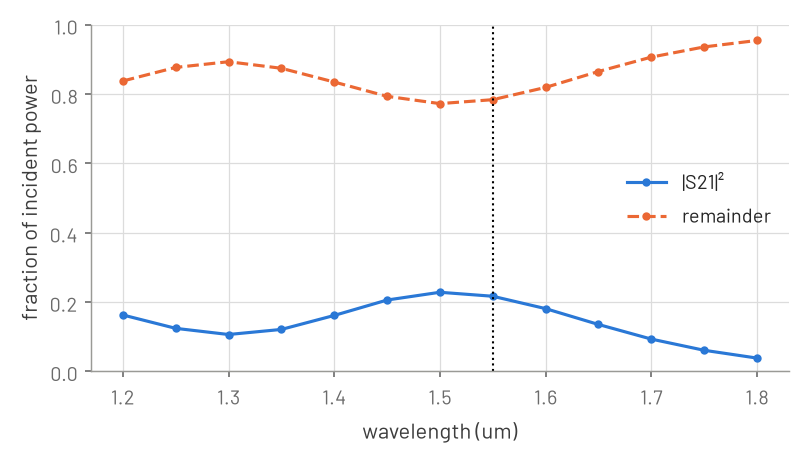

In [13]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(in_um, t_band, marker="o", ms=3, label="|S21|²")
ax.plot(in_um, remainder_band, ls="--", marker="o", ms=3, label="remainder")
ax.axvline(settings["wavelength_um"], color="k", ls=":", lw=1)
ax.set_ylim(0, 1)
ax.set_xlabel("wavelength (um)")
ax.set_ylabel("fraction of incident power")
ax.legend(loc="center right");

## Trust: the mirror, the mesh and the box

Re-solves of `final` at 1.55 µm, each against the mirror half model value above as
ΔT, the change in |S21|²:

- **The mirror.** The full stack at the same h, with no PMC: twice the volume,
  in its own process. Its S-matrix should equal the mirror half model's to the
  solver's precision.
- **The mesh.** The mirror half model at h = 0.07 µm, with six cells through the
  core and finer oxide cells, solved iteratively (BDDC + GMRES to a relative residual
  of 10⁻⁶). The pixels are re-sampled on the finer mesh too, so ΔT moves the
  material and the field together: it is the mesh error quoted for this design.
- **The box.** A 7 µm × 7 µm box (`box=3.5`): the absorbing boundary 2 µm from the
  design in plane instead of 1 µm. Inside the 5 µm box the mesh is the same node for
  node, so the same pixels apply.
- **Eroded and dilated.** `design.robust` projects the filtered last iterate at
  thresholds 0.6, 0.5 and 0.4 (β = 64, δ = 0.1), as an over- or under-etch would
  thin or widen every core strip. These are projected densities, so they are read
  against the robust nominal's |S21|², not against `final`'s.

In [14]:
print(
    f"final, mirror half model, h = {optimized_on['h_um']} um: |S21|^2 = {t_final:.4f}"
)
for name, key, stage in (
    ("full stack", "s_final_full", "full"),
    ("finer mesh", "s_final_h007", "fine"),
    (f"{2 * geometry['box_7um_half_width_um']:g} um box", "s_final_box7", "box"),
):
    m, t = mesh(stage), transmission(key)
    resources = seen[stage]
    print(
        f"{name}: h = {m['h_um']} um, {m['dof']:,} DOF, |S21|^2 = {t:.4f}, "
        f"delta T = {t - t_final:+.1e} ({resources['wall_s'] / 60:.1f} min, "
        f"peak {resources['peak_rss_bytes'] / 2**30:.1f} GiB)"
    )
print(
    "full stack against mirror half model: max |delta S| = "
    f"{np.abs(out['s_final_full'] - out['s_final']).max():.1e}"
)
iterations = seen["fine"]["gmres_iterations"]
print(f"finer mesh: GMRES iterations per solved column: {iterations}")
t_eroded = report("eroded", "s_eroded")
t_nominal = report("robust nominal", "s_nominal")
t_dilated = report("dilated", "s_dilated")

final, mirror half model, h = 0.1 um: |S21|^2 = 0.2161
full stack: h = 0.1 um, 2,137,244 DOF, |S21|^2 = 0.2161, delta T = +4.8e-14 (3.4 min, peak 52.8 GiB)
finer mesh: h = 0.07 um, 3,594,224 DOF, |S21|^2 = 0.2160, delta T = -6.5e-05 (20.2 min, peak 32.3 GiB)
7 um box: h = 0.1 um, 2,112,902 DOF, |S21|^2 = 0.2151, delta T = -1.0e-03 (1.9 min, peak 42.8 GiB)
full stack against mirror half model: max |delta S| = 1.6e-13
finer mesh: GMRES iterations per solved column: [133, 133, 133, 133, 133, 133]
eroded: |S21|^2 = 0.2088, |S11|^2 = 1.0e-04, remainder = 0.7911
robust nominal: |S21|^2 = 0.2162, |S11|^2 = 4.1e-04, remainder = 0.7834
dilated: |S21|^2 = 0.2038, |S11|^2 = 2.1e-05, remainder = 0.7962


The full stack moves |S21|² by 4.8 × 10⁻¹⁴ and the S-matrix by at most
1.6 × 10⁻¹³: the mirror half model gives the full stack's answer to the solver's
precision. The finer mesh moves |S21|² by -6.5 × 10⁻⁵ and the larger box by
-1.0 × 10⁻³. The eroded and dilated designs transmit 0.2088 and 0.2038, against
0.2162 for the robust nominal. None of these comes near the gap between 0.216 and
1: that gap belongs to the design in this stack and this square.

## The fields

|E| with 1 W incident in the fundamental mode at p1, for the arc design and for
`final`. Top row, the core mid-plane z = 0; the blue line is the core edge
(ρ = 0.5). Bottom row, the cross-section of the output guide at y = -2.0 µm,
mirrored to the full height, where power radiated out of the plane shows above
and below the guide; the blue rectangle is the core. Each design's maps are scaled
to its peak |E| in the input guide's part of the mid-plane, on one grey scale. They
are amplitudes, the square root of a power, so weak radiation shows more strongly
than its share of the power.

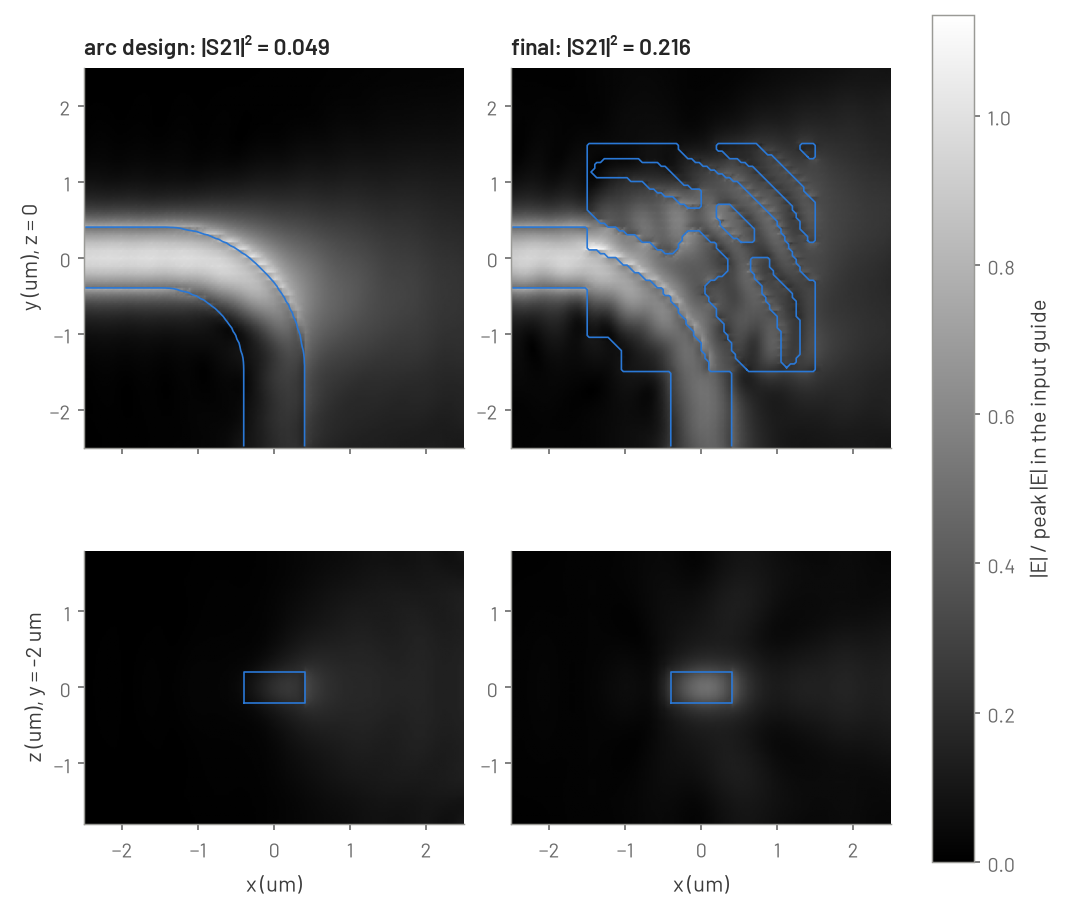

In [15]:
designs = {
    f"arc design: |S21|² = {t_arc:.3f}": ("arc", out["arc"]),
    f"final: |S21|² = {t_final:.3f}": ("final", final),
}
maps = {
    title: (
        density,
        out[f"cut_top_{name}"].astype(float) / input_peak[name],
        mirrored(out[f"cut_out_{name}"]).T / input_peak[name],
    )
    for title, (name, density) in designs.items()
}
vmax = max(max(top.max(), cross.max()) for _, top, cross in maps.values())
fig, axes = plt.subplots(
    2,
    2,
    figsize=(7, 6),
    sharex=True,
    height_ratios=[2 * HALF, 2 * Z_TOP],
    layout="constrained",
)
for (top_ax, cross_ax), (title, (density, top, cross)) in zip(
    axes.T, maps.items(), strict=True
):
    image = top_ax.imshow(
        top, origin="lower", extent=EXTENT, cmap="gray", vmin=0, vmax=vmax
    )
    for line in contour_generator(centres, centres, window(density)).lines(0.5):
        top_ax.plot(*line.T, color="C0", ls="-", lw=0.8)
    top_ax.set_title(title)
    cross_ax.imshow(
        cross,
        origin="lower",
        extent=[-HALF, HALF, -Z_TOP, Z_TOP],
        cmap="gray",
        vmin=0,
        vmax=vmax,
    )
    cross_ax.plot(*(box * [GUIDE, CORE_HALF]).T, color="C0", ls="-", lw=0.8)
    cross_ax.set_xlabel("x (um)")
    for ax in (top_ax, cross_ax):
        ax.grid(False)
axes[0, 0].set_ylabel("y (um), z = 0")
axes[1, 0].set_ylabel(f"z (um), y = {cuts['cut_out_y_um']:g} um")
fig.colorbar(image, ax=axes, label="|E| / peak |E| in the input guide");

In the arc design the field spreads off the arc's outer edge into the oxide
outside the bend, and little of it reaches the output guide's cross-section. In
`final` the field follows the wide inner strip into the output guide, and part of
it spreads among the outer strips. Around the output guide's cross-section, the
field outside the core is weak above and below; the flux above puts the power that
leaves the plane at 0.091 of the delivered power.

## Against the 2D bend

The two tutorials pose different problems, so their numbers are not compared here;
the [2D tutorial](bend.ipynb) gives its own. In words: its design turns nearly all
of the power, and this one about a fifth. The recipe is the same; the guides are
not.

- The 2D slab model has its electric field normal to the plane (TM-like) and takes
  2.25 for its core against 1.444 for its cladding, effective indices that stand
  for a stack. Its 0.55 µm guides also carry a second mode.
- This stack's mode is TE-like, and its indices are the materials' own, 1.996 and
  1.444. A core 0.4 µm thick holds the mode at n_eff = 1.5995, close to the oxide's
  index, with a field that falls by 1/e every 0.36 µm into the oxide. Its 0.8 µm
  guides are single-mode.

At the 1.5 µm radius the square allows, the arc keeps 0.049 of the power; free to
place nitride anywhere in the square, the optimization reaches 0.216. The 2D design
does not fit these guides, so it is not re-solved here.

## Limits

- **Not run in CI.** The numbers come from one run of `tools/bend3d_run.py` at the
  gfem commit and on the machine printed at the top; the page re-reads them and
  solves nothing. A change to the script or its mesh builder stops the page (the
  hash check); a change to gfem does not, so the numbers are those of gfem at that
  commit.
- **One square, one stack, one start.** 0.216 is for a 0.4 µm Si3N4 core in a
  3 µm × 3 µm square, from one gradient-based run that starts from a uniform 0.5.
  It is the design this run found, not a bound on what any pattern could do. A
  larger square, a thicker nitride core or a silicon core would confine or turn the
  mode differently; each needs a new run of the script.
- **No substrate.** The oxide is 1.6 µm above and below the core, with no silicon
  under it, which assumes a thick buried oxide. Leakage into a substrate is not
  modelled.
- **An absorbing boundary, not a PML.** Second-order absorbing faces 1 µm from the
  design in plane and 1.6 µm from the core vertically. The straight guide loses
  6.7 × 10⁻⁴ over 5 µm with no bend; the 7 µm × 7 µm box moves |S21|² by
  -1.0 × 10⁻³, a bound for this design only. The vertical margin is not varied.
- **The mesh is part of the material model.** Each element takes the pixel image
  at its centroid. The h = 0.07 µm re-solve changes the sampling and the field
  together, so its ΔT, -6.5 × 10⁻⁵, is the quoted mesh error, at 1.55 µm only.
- **Constant indices.** The indices are those at 1.55 µm, and the spectrum ignores
  their dispersion: over the band Si3N4 runs from 2.0065 to 1.9893 and SiO2 from
  1.4481 to 1.4409 (the Sellmeier values printed in "The stack"). Lossless media.
- **A symmetric, ideal stack.** The mirror half model imposes z symmetry: vertical
  sidewalls, a full etch, the same oxide above and below, and a design uniform
  through the core. A fabricated asymmetry would couple the TE-like mode to TM-like
  ones, which this model cannot represent.
- **One wavelength and a filter length scale.** The objective is |S21|² at
  1.55 µm; the spectrum is evaluated, not optimized, and |S21|² falls to 0.0377 at
  1.8 µm. The 0.3 µm filter gives a length scale but no guaranteed minimum width;
  the eroded and dilated designs transmit 0.2088 and 0.2038, against 0.2162 for
  the robust nominal.
- **The out-of-plane share is an estimate.** It comes from sampled-field fluxes:
  P_in exceeds 1 - |S11|² by 6.6 × 10⁻³ W, against a share of 0.091.
- **2D and 3D are not like for like.** The polarization, the indices and the guide
  width differ; the page compares them in words, not in numbers.

## Next

- [The 2D bend tutorial](bend.ipynb): the same recipe, run end to end in its
  notebook.
- [Measurements](../recipes/measurements.md): `Field.at` and `Field.b()`, the
  probes behind the field cuts and the fluxes.
- [S-parameter gradients](../recipes/s-parameter-gradient.md): what is
  differentiable in a driven solve.
- `tools/bend3d_run.py`: the run itself. `just bend3d-data` reruns every stage and
  rewrites the run record, about 1 h on 16 cores and 64 GiB with the `mkl` extra
  (`uv run --extra mkl --group docs`); `--profile smoke` runs the same stages on
  coarse meshes in minutes, for development.